## 1. Setup: import, konfigurasi, dan reproduksibilitas

In [ ]:
import os, json, time, random, copy, platform, warnings, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models, transforms, datasets

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore", category=UserWarning)
print("Python     :", platform.python_version())
print("PyTorch    :", torch.__version__)
print("torchvision:", torchvision.__version__)
print("CUDA       :", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

Python     : 3.13.15
PyTorch    : 2.11.0+cu130
torchvision: 0.26.0+cu130
CUDA       : True Tesla T4


In [ ]:
# ===================== KONFIGURASI EKSPERIMEN =====================
SMOKE_TEST = False      # True = cek cepat pipeline dengan data sintetis (hasil TIDAK untuk laporan)
RESUME     = True       # lewati kondisi yang sudah selesai (berguna jika Colab terputus)

SEED         = 42
BATCH_SIZE   = 32
NUM_WORKERS  = 2
WEIGHT_DECAY = 1e-2
PATIENCE     = 5                                  # early stopping pada validation loss
MAX_EPOCHS   = {"scratch": 40, "default": 25}     # batas atas; early stopping biasanya berhenti lebih awal

LR_SCRATCH   = 1e-3
LR_HEAD      = 1e-3
LR_LASTBLOCK = 1e-4

B4_BASE_STRATEGY = "finetune_last"                # B4 dijalankan di atas konfigurasi B3
RUN_B5   = True
B5_ARCHS = ["efficientnet_b0", "mobilenet_v3_small"]

# 5 ras kucing + 5 ras anjing (nama mengikuti torchvision OxfordIIITPet.classes).
# Sengaja menyertakan pasangan yang mirip (Birman/Ragdoll/Siamese, Pit Bull/Staffordshire)
# agar failure analysis bermakna.
CAT_BREEDS = ["Abyssinian", "Bengal", "Birman", "Ragdoll", "Siamese"]
DOG_BREEDS = ["American Pit Bull Terrier", "Staffordshire Bull Terrier", "Beagle", "Basset Hound", "Samoyed"]
SELECTED_CLASSES = CAT_BREEDS + DOG_BREEDS
NUM_CLASSES = len(SELECTED_CLASSES)

DATA_ROOT = Path("./data")
OUT_DIR   = Path("./results_smoke" if SMOKE_TEST else "./results")
FIG_DIR, RUN_DIR, MODEL_DIR = OUT_DIR / "figures", OUT_DIR / "runs", OUT_DIR / "models"
for d in (FIG_DIR, RUN_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

if SMOKE_TEST:
    MAX_EPOCHS = {"scratch": 2, "default": 2}
    PATIENCE = 1

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| Output dir:", OUT_DIR)

Device: cuda | Output dir: results


In [ ]:
def set_seed(seed: int = SEED):
    """Kunci seluruh sumber keacakan: Python, NumPy, PyTorch (CPU & CUDA), cuDNN."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    """Seed tiap worker DataLoader agar augmentasi acak juga reproducible."""
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

set_seed(SEED)

CONFIG = {
    "seed": SEED, "batch_size": BATCH_SIZE, "optimizer": "AdamW", "weight_decay": WEIGHT_DECAY,
    "loss": "CrossEntropyLoss", "early_stopping": {"monitor": "val_loss", "patience": PATIENCE, "restore_best": True},
    "max_epochs": MAX_EPOCHS, "lr": {"scratch": LR_SCRATCH, "head": LR_HEAD, "last_block": LR_LASTBLOCK},
    "input_size": 224, "normalization": {"mean": [0.485, 0.456, 0.406], "std": [0.229, 0.224, 0.225]},
    "classes": SELECTED_CLASSES, "split": {"train": 0.70, "val": 0.15, "test": 0.15, "stratified": True},
    "smoke_test": SMOKE_TEST,
    "env": {"python": platform.python_version(), "torch": torch.__version__, "torchvision": torchvision.__version__,
            "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"},
}
with open(OUT_DIR / "config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)
print(json.dumps(CONFIG["env"], indent=2))

{
  "python": "3.13.15",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "gpu": "Tesla T4"
}


## 2. Dataset: subset 10 kelas Oxford-IIIT Pet + split stratified 70/15/15

Catatan desain:
- Split resmi `trainval` dan `test` dari torchvision **digabung**, lalu dibagi ulang secara stratified 70/15/15 sesuai aturan tugas. Pembagian dilakukan **sekali** dengan `random_state=SEED` dan disimpan ke `split.csv` sebagai bukti tidak ada kebocoran data.
- Citra di-*cache* di RAM setelah di-resize (sisi terpendek 256 px). Ini setara dengan langkah `Resize(256)` pada pipeline transformasi, sehingga hasil tidak berubah, tetapi epoch jauh lebih cepat karena JPEG tidak di-decode ulang setiap epoch.

In [ ]:
CACHE_RESIZE = transforms.Resize(256)   # sama dengan langkah pertama pipeline train & eval

def _make_synthetic(n_per_class=12, size=(300, 260)):
    """Data sintetis untuk SMOKE_TEST: tiap kelas punya warna dasar berbeda + noise."""
    rng = np.random.default_rng(SEED)
    imgs, labels, ids = [], [], []
    for c in range(NUM_CLASSES):
        base = rng.integers(0, 255, size=3)
        for k in range(n_per_class):
            arr = np.clip(base + rng.normal(0, 40, size=(size[1], size[0], 3)), 0, 255).astype(np.uint8)
            imgs.append(CACHE_RESIZE(Image.fromarray(arr)))
            labels.append(c); ids.append(f"synthetic_{c}_{k}.jpg")
    return imgs, np.array(labels), ids

def load_pet_subset():
    if SMOKE_TEST:
        return _make_synthetic()
    parts = [datasets.OxfordIIITPet(DATA_ROOT, split=s, target_types="category", download=True)
             for s in ("trainval", "test")]
    class_names = parts[0].classes
    missing = [c for c in SELECTED_CLASSES if c not in class_names]
    assert not missing, f"Kelas tidak ditemukan: {missing}\nTersedia: {class_names}"
    remap = {name: i for i, name in enumerate(SELECTED_CLASSES)}

    imgs, labels, ids = [], [], []
    for ds in parts:
        for path, y in zip(ds._images, ds._labels):
            name = class_names[y]
            if name in remap:
                with Image.open(path) as im:
                    imgs.append(CACHE_RESIZE(im.convert("RGB")))
                labels.append(remap[name]); ids.append(Path(path).name)
    return imgs, np.array(labels), ids

t0 = time.time()
IMAGES, LABELS, IMAGE_IDS = load_pet_subset()
print(f"Loaded {len(IMAGES)} images in {time.time()-t0:.1f}s")
print(pd.Series(LABELS).map(dict(enumerate(SELECTED_CLASSES))).value_counts().sort_index().to_string())

100%|██████████| 792M/792M [00:30<00:00, 26.0MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.9MB/s]


Loaded 1986 images in 57.4s
Abyssinian                    198
American Pit Bull Terrier     200
Basset Hound                  200
Beagle                        200
Bengal                        200
Birman                        200
Ragdoll                       200
Samoyed                       200
Siamese                       199
Staffordshire Bull Terrier    189


In [ ]:
all_idx = np.arange(len(LABELS))
train_idx, temp_idx = train_test_split(all_idx, test_size=0.30, stratify=LABELS, random_state=SEED)
val_idx, test_idx   = train_test_split(temp_idx, test_size=0.50, stratify=LABELS[temp_idx], random_state=SEED)

# Bukti tidak ada data leakage antar split
assert set(train_idx).isdisjoint(val_idx) and set(train_idx).isdisjoint(test_idx) and set(val_idx).isdisjoint(test_idx)
assert len(train_idx) + len(val_idx) + len(test_idx) == len(LABELS)

split_df = pd.DataFrame({
    "index": all_idx, "image_id": IMAGE_IDS, "label": LABELS,
    "class_name": [SELECTED_CLASSES[y] for y in LABELS],
    "split": "train",
})
split_df.loc[val_idx, "split"] = "val"
split_df.loc[test_idx, "split"] = "test"
split_df.to_csv(OUT_DIR / "split.csv", index=False)

print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")
display(pd.crosstab(split_df["class_name"], split_df["split"])[["train", "val", "test"]])

train=1390  val=298  test=298


split,train,val,test
class_name,,,
Abyssinian,139,29,30
American Pit Bull Terrier,140,30,30
Basset Hound,140,30,30
Beagle,140,30,30
Bengal,140,30,30
Birman,140,30,30
Ragdoll,140,30,30
Samoyed,140,30,30
Siamese,139,30,30


## 3. Pipeline transformasi

- **Train + augmentasi** (dipakai B1, B2, B3, B4b, B5): sama persis dengan starter code (RandomResizedCrop, HorizontalFlip, Rotation 15°, ColorJitter).
- **Train tanpa augmentasi** (B4a): hanya Resize + CenterCrop + Normalisasi.
- **Validation / test**: `weights.transforms()` (deterministik, tanpa distorsi). Augmentasi **tidak pernah** dipakai pada val/test.

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


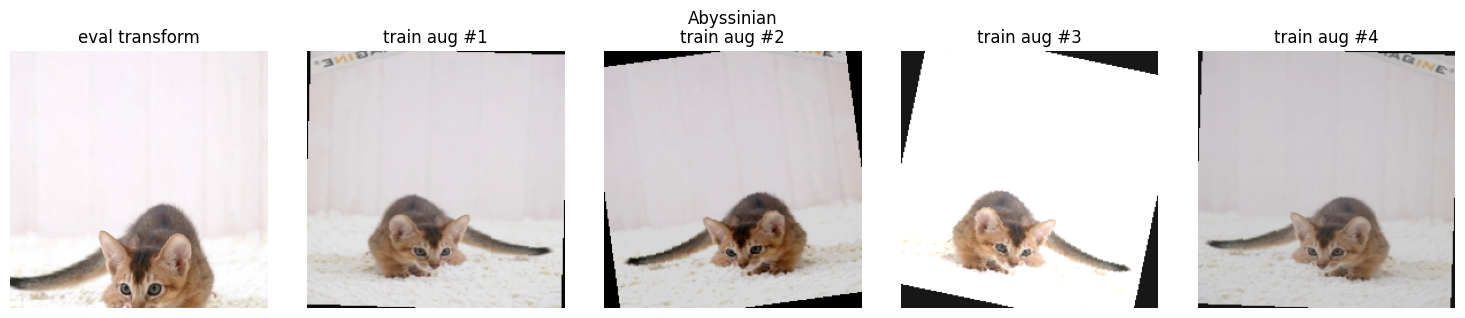

In [ ]:
RESNET_WEIGHTS = models.ResNet18_Weights.IMAGENET1K_V1
eval_transforms = RESNET_WEIGHTS.transforms()
MEAN, STD = eval_transforms.mean, eval_transforms.std

train_transforms_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

train_transforms_noaug = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

print(eval_transforms)

class PetSubset(Dataset):
    """Mengembalikan (tensor, label, index_global) agar prediksi bisa dilacak ke citra aslinya."""
    def __init__(self, indices, transform):
        self.indices = list(indices)
        self.transform = transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        j = self.indices[i]
        return self.transform(IMAGES[j]), int(LABELS[j]), j

def make_loader(indices, transform, shuffle):
    g = torch.Generator()
    g.manual_seed(SEED)
    return DataLoader(PetSubset(indices, transform), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, worker_init_fn=seed_worker, generator=g,
                      pin_memory=torch.cuda.is_available())

def denormalize(t):
    m = torch.tensor(MEAN).view(3, 1, 1); s = torch.tensor(STD).view(3, 1, 1)
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

# Visual check: augmentasi hanya di train
set_seed(SEED)
sample_j = int(train_idx[0])
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
axes[0].imshow(denormalize(eval_transforms(IMAGES[sample_j]))); axes[0].set_title("eval transform")
for k in range(1, 5):
    axes[k].imshow(denormalize(train_transforms_aug(IMAGES[sample_j]))); axes[k].set_title(f"train aug #{k}")
for a in axes: a.axis("off")
plt.suptitle(SELECTED_CLASSES[LABELS[sample_j]]); plt.tight_layout()
plt.savefig(FIG_DIR / "augmentation_examples.png", dpi=120); plt.show()

## 4. Model builder dan strategi pembekuan

`build_model` mengembalikan `(model, head, last_block)` sehingga strategi yang sama bisa dipakai lintas arsitektur:

| Arsitektur | `head` | `last_block` (dibuka pada fine-tuning) |
|---|---|---|
| ResNet-18 | `fc` → `Linear(512, 10)` | `layer4` |
| EfficientNet-B0 | `classifier[1]` → `Linear(1280, 10)` | `features[6:]` (dua stage terakhir + conv 1×1 akhir) |
| MobileNetV3-Small | `classifier` (dengan `Linear(1024, 10)` di akhir) | `features[9:]` (tiga blok terakhir + conv akhir) |

**Catatan penting BatchNorm pada lapisan beku.** `requires_grad = False` hanya menghentikan update bobot (γ, β). Dalam mode `train()`, *running mean/var* BatchNorm tetap ter-update oleh statistik mini-batch data baru, sehingga backbone yang "dibekukan" sebenarnya tetap berubah. Fungsi `set_train_mode` di bawah memaksa setiap sub-modul yang seluruh parameternya beku tetap dalam mode `eval()` (BatchNorm memakai running stats ImageNet, stochastic depth EfficientNet nonaktif), agar bagian beku benar-benar memakai representasi pretrained asli (kaitkan dengan Slide 6–8 dan 28).

In [ ]:
def build_model(arch: str, pretrained: bool):
    use_w = pretrained and not SMOKE_TEST
    if arch == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if use_w else None)
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
        head, last = m.fc, m.layer4
    elif arch == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if use_w else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)
        head, last = m.classifier, m.features[6:]
    elif arch == "mobilenet_v3_small":
        m = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1 if use_w else None)
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, NUM_CLASSES)
        head, last = m.classifier, m.features[9:]
    else:
        raise ValueError(arch)
    return m, head, last

def freeze_all(module):
    for p in module.parameters():
        p.requires_grad = False

def unfreeze(module):
    for p in module.parameters():
        p.requires_grad = True

def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

def set_train_mode(model):
    """model.train(), tetapi setiap sub-modul yang SELURUH parameternya beku diset eval():
    BatchNorm-nya tidak meng-update running stats dan stochastic depth/dropout di dalamnya nonaktif."""
    model.train()
    for mod in model.modules():
        ps = list(mod.parameters())
        if ps and not any(p.requires_grad for p in ps):
            mod.eval()

def configure_strategy(model, head, last, strategy):
    """Atur requires_grad dan kembalikan param groups (nama, modul, lr) untuk AdamW."""
    if strategy == "scratch":
        unfreeze(model)
        return [("all", model, LR_SCRATCH)]
    if strategy == "feature_extraction":
        freeze_all(model); unfreeze(head)
        return [("head", head, LR_HEAD)]
    if strategy == "finetune_last":
        freeze_all(model); unfreeze(last); unfreeze(head)
        return [("last_block", last, LR_LASTBLOCK), ("head", head, LR_HEAD)]
    raise ValueError(strategy)

# Verifikasi sesuai Tips Implementasi: B2 pada ResNet-18 harus ~5.130 trainable params
_m, _h, _l = build_model("resnet18", pretrained=False)
configure_strategy(_m, _h, _l, "feature_extraction")
print("B2 trainable params:", f"{count_params(_m)[0]:,} / {count_params(_m)[1]:,}")
assert count_params(_m)[0] == 512 * NUM_CLASSES + NUM_CLASSES
del _m, _h, _l

B2 trainable params: 5,130 / 11,181,642


## 5. Training engine (early stopping, logging, evaluasi)

Untuk setiap kondisi dicatat: trainable params, LR per param group, riwayat loss/akurasi per epoch, epoch terbaik (konvergen), durasi total, puncak memori GPU, akurasi & Macro F1 validasi, akurasi train "bersih" (tanpa augmentasi, untuk mengukur *generalization gap*), akurasi & **Macro F1 test**, serta latensi inferensi.

Pemilihan model terbaik dan konfigurasi B5 **hanya** memakai metrik validasi; test set hanya dipakai untuk pelaporan akhir.

In [ ]:
CRITERION = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    set_train_mode(model) if training else model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y, _ in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            out = model(x)
            loss = CRITERION(out, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, ys, idxs = [], [], []
    for x, y, j in loader:
        probs.append(F.softmax(model(x.to(device)), dim=1).cpu())
        ys.append(y); idxs.append(j)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy(), torch.cat(idxs).numpy()

@torch.no_grad()
def measure_latency(model, dev, batch_size, iters):
    model = model.to(dev).eval()
    x = torch.randn(batch_size, 3, 224, 224, device=dev)
    for _ in range(3):
        model(x)
    if dev.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(iters):
        model(x)
    if dev.type == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) / iters * 1000.0  # ms per batch

RESULTS = {}          # code -> dict(summary, history, preds, state_dict)

In [ ]:
def save_logs():
    """Tulis seluruh log mentah dari kondisi yang sudah selesai (dipanggil setiap selesai satu kondisi)."""
    if not RESULTS:
        return
    hist = pd.concat([pd.DataFrame(r["history"]) for r in RESULTS.values()], ignore_index=True)
    hist.to_csv(OUT_DIR / "epoch_log.csv", index=False)
    summ = pd.DataFrame([r["summary"] for r in RESULTS.values()])
    summ.to_csv(OUT_DIR / "summary.csv", index=False)
    with open(OUT_DIR / "summary.json", "w") as f:
        json.dump({"config": CONFIG, "conditions": [r["summary"] for r in RESULTS.values()]}, f, indent=2)
    rows = []
    for code, r in RESULTS.items():
        p = r["test_probs"]; pred = p.argmax(1)
        for k, j in enumerate(r["test_idx"]):
            rows.append({"condition": code, "index": int(j), "image_id": IMAGE_IDS[j],
                         "true": SELECTED_CLASSES[r["test_y"][k]], "pred": SELECTED_CLASSES[pred[k]],
                         "confidence": float(p[k, pred[k]]), "p_true": float(p[k, r["test_y"][k]]),
                         "correct": bool(pred[k] == r["test_y"][k])})
    pd.DataFrame(rows).to_csv(OUT_DIR / "test_predictions.csv", index=False)

def train_condition(code, desc, arch, strategy, augment):
    run_file, model_file = RUN_DIR / f"{code}.json", MODEL_DIR / f"{code}.pt"
    if RESUME and run_file.exists() and model_file.exists():
        with open(run_file) as f:
            saved = json.load(f)
        saved["test_probs"] = np.array(saved["test_probs"]); saved["test_y"] = np.array(saved["test_y"])
        saved["test_idx"] = np.array(saved["test_idx"])
        saved["state_dict"] = torch.load(model_file, map_location="cpu")
        RESULTS[code] = saved; save_logs()
        print(f"[{code}] dimuat dari hasil sebelumnya (RESUME=True).")
        return

    set_seed(SEED)
    model, head, last = build_model(arch, pretrained=(strategy != "scratch"))
    groups = configure_strategy(model, head, last, strategy)
    model.to(device)
    optimizer = torch.optim.AdamW(
        [{"params": [p for p in mod.parameters() if p.requires_grad], "lr": lr, "name": name}
         for name, mod, lr in groups],
        weight_decay=WEIGHT_DECAY)
    trainable, total = count_params(model)
    lr_str = "; ".join(f"{g['name']}={g['lr']:g}" for g in optimizer.param_groups)
    print(f"\n=== {code}: {desc} | {arch} | {strategy} | aug={augment}")
    print(f"Trainable params: {trainable:,} / {total:,} ({100*trainable/total:.2f}%) | LR: {lr_str}")

    train_loader = make_loader(train_idx, train_transforms_aug if augment else train_transforms_noaug, shuffle=True)
    val_loader   = make_loader(val_idx, eval_transforms, shuffle=False)
    test_loader  = make_loader(test_idx, eval_transforms, shuffle=False)
    train_eval_loader = make_loader(train_idx, eval_transforms, shuffle=False)

    max_ep = MAX_EPOCHS["scratch" if strategy == "scratch" else "default"]
    best_loss, best_epoch, best_state, bad, history = float("inf"), 0, None, 0, []
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t_start = time.perf_counter()
    for ep in range(1, max_ep + 1):
        t_ep = time.perf_counter()
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader)
        ep_time = time.perf_counter() - t_ep
        history.append({"condition": code, "epoch": ep, "train_loss": tr_loss, "train_acc": tr_acc,
                        "val_loss": va_loss, "val_acc": va_acc, "epoch_time_s": ep_time,
                        **{f"lr_{g['name']}": g["lr"] for g in optimizer.param_groups}})
        improved = va_loss < best_loss - 1e-4
        print(f"  ep {ep:02d} | train {tr_loss:.4f}/{tr_acc:.3f} | val {va_loss:.4f}/{va_acc:.3f} | {ep_time:.1f}s" + (" *" if improved else ""))
        if improved:
            best_loss, best_epoch, bad = va_loss, ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"  Early stopping (patience={PATIENCE}); bobot dikembalikan ke epoch {best_epoch}.")
                break
    if device.type == "cuda": torch.cuda.synchronize()
    train_time = time.perf_counter() - t_start
    peak_mem = torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else float("nan")

    model.load_state_dict(best_state)
    best_row = history[best_epoch - 1]
    val_probs, val_y, _ = predict(model, val_loader)
    test_probs, test_y, test_ids = predict(model, test_loader)
    _, train_acc_clean = run_epoch(model, train_eval_loader)

    lat_gpu = measure_latency(model, device, 32, 20 if not SMOKE_TEST else 2) if device.type == "cuda" else float("nan")
    lat_cpu = measure_latency(copy.deepcopy(model), torch.device("cpu"), 1, 20 if not SMOKE_TEST else 2)
    model.to(device)

    summary = {
        "condition": code, "description": desc, "arch": arch, "strategy": strategy, "augmentation": augment,
        "trainable_params": trainable, "total_params": total, "trainable_pct": round(100 * trainable / total, 3),
        "lr_groups": lr_str, "epochs_run": len(history), "best_epoch": best_epoch,
        "early_stopped": len(history) < max_ep, "train_time_s": round(train_time, 2),
        "time_per_epoch_s": round(train_time / len(history), 2), "peak_gpu_mem_mb": round(peak_mem, 1),
        "best_val_loss": round(best_loss, 4), "val_acc": round(best_row["val_acc"], 4),
        "val_macro_f1": round(f1_score(val_y, val_probs.argmax(1), average="macro"), 4),
        "train_acc_running_at_best": round(best_row["train_acc"], 4),
        "train_acc_clean": round(train_acc_clean, 4),
        "gap_train_clean_minus_val": round(train_acc_clean - best_row["val_acc"], 4),
        "test_acc": round(accuracy_score(test_y, test_probs.argmax(1)), 4),
        "test_macro_f1": round(f1_score(test_y, test_probs.argmax(1), average="macro"), 4),
        "latency_gpu_ms_per_batch32": round(lat_gpu, 2), "latency_cpu_ms_per_img": round(lat_cpu, 2),
        "seed": SEED,
    }
    RESULTS[code] = {"summary": summary, "history": history, "test_probs": test_probs, "test_y": test_y,
                     "test_idx": test_ids, "state_dict": best_state}
    torch.save(best_state, model_file)
    with open(run_file, "w") as f:
        json.dump({"summary": summary, "history": history, "test_probs": test_probs.tolist(),
                   "test_y": test_y.tolist(), "test_idx": test_ids.tolist()}, f)
    save_logs()
    print(f"  -> best epoch {best_epoch} | val acc {summary['val_acc']:.4f} | test macro F1 {summary['test_macro_f1']:.4f} | {train_time:.0f}s")
    del model, optimizer
    if device.type == "cuda": torch.cuda.empty_cache()

## 6. Eksperimen B1–B4

Semua kondisi memakai seed, split, batch size, optimizer, dan kriteria early stopping yang sama. Seed di-reset di awal setiap kondisi sehingga urutan data dan inisialisasi head identik antar kondisi.

### B1 — Baseline from scratch (`weights=None`)

In [ ]:
train_condition("B1", "Baseline from scratch", "resnet18", "scratch", augment=True)


=== B1: Baseline from scratch | resnet18 | scratch | aug=True
Trainable params: 11,181,642 / 11,181,642 (100.00%) | LR: all=0.001
  ep 01 | train 2.3514/0.174 | val 2.6791/0.238 | 9.9s *
  ep 02 | train 2.0819/0.230 | val 2.5577/0.121 | 8.2s *
  ep 03 | train 2.0435/0.243 | val 2.0514/0.201 | 7.5s *
  ep 04 | train 1.9210/0.287 | val 2.0189/0.295 | 7.6s *
  ep 05 | train 1.8643/0.322 | val 1.7616/0.342 | 8.2s *
  ep 06 | train 1.7670/0.350 | val 2.1831/0.295 | 6.9s
  ep 07 | train 1.7260/0.359 | val 1.6809/0.372 | 8.3s *
  ep 08 | train 1.6491/0.388 | val 1.8002/0.329 | 9.4s
  ep 09 | train 1.6343/0.401 | val 1.6990/0.342 | 11.8s
  ep 10 | train 1.5420/0.436 | val 1.7968/0.362 | 8.1s
  ep 11 | train 1.5036/0.453 | val 1.6292/0.413 | 8.1s *
  ep 12 | train 1.5356/0.446 | val 1.6035/0.423 | 7.3s *
  ep 13 | train 1.4381/0.475 | val 1.6262/0.426 | 8.4s
  ep 14 | train 1.3786/0.483 | val 1.5806/0.433 | 7.1s *
  ep 15 | train 1.3206/0.506 | val 1.7740/0.393 | 8.3s
  ep 16 | train 1.2513/0.

### B2 — Feature extraction (backbone beku, hanya `fc`)

In [ ]:
train_condition("B2", "Feature extraction", "resnet18", "feature_extraction", augment=True)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 179MB/s]



=== B2: Feature extraction | resnet18 | feature_extraction | aug=True
Trainable params: 5,130 / 11,181,642 (0.05%) | LR: head=0.001
  ep 01 | train 1.3787/0.576 | val 0.7484/0.755 | 6.6s *
  ep 02 | train 0.6247/0.826 | val 0.5054/0.819 | 7.4s *
  ep 03 | train 0.4925/0.846 | val 0.4864/0.802 | 8.4s *
  ep 04 | train 0.4111/0.878 | val 0.4202/0.849 | 6.3s *
  ep 05 | train 0.3750/0.885 | val 0.3721/0.866 | 7.7s *
  ep 06 | train 0.3338/0.894 | val 0.3717/0.859 | 6.2s *
  ep 07 | train 0.3311/0.881 | val 0.3506/0.872 | 7.6s *
  ep 08 | train 0.3033/0.904 | val 0.3428/0.872 | 6.3s *
  ep 09 | train 0.2776/0.915 | val 0.3746/0.839 | 7.6s
  ep 10 | train 0.2820/0.906 | val 0.3852/0.839 | 6.4s
  ep 11 | train 0.2670/0.906 | val 0.3656/0.846 | 7.7s
  ep 12 | train 0.2744/0.908 | val 0.3637/0.862 | 6.2s
  ep 13 | train 0.2501/0.922 | val 0.3661/0.836 | 7.5s
  Early stopping (patience=5); bobot dikembalikan ke epoch 8.
  -> best epoch 8 | val acc 0.8725 | test macro F1 0.8706 | 92s


### B3 — Progressive fine-tuning (`layer4` + `fc`, differential LR)

In [ ]:
train_condition("B3", "Progressive fine-tuning (layer4+fc)", "resnet18", "finetune_last", augment=True)


=== B3: Progressive fine-tuning (layer4+fc) | resnet18 | finetune_last | aug=True
Trainable params: 8,398,858 / 11,181,642 (75.11%) | LR: last_block=0.0001; head=0.001
  ep 01 | train 0.8804/0.709 | val 0.3350/0.856 | 7.6s *
  ep 02 | train 0.3055/0.897 | val 0.4000/0.842 | 6.2s
  ep 03 | train 0.2118/0.930 | val 0.2794/0.883 | 7.6s *
  ep 04 | train 0.1372/0.955 | val 0.3499/0.872 | 6.1s
  ep 05 | train 0.0890/0.977 | val 0.3038/0.883 | 7.6s
  ep 06 | train 0.0503/0.989 | val 0.3258/0.883 | 6.3s
  ep 07 | train 0.0462/0.991 | val 0.3760/0.879 | 7.5s
  ep 08 | train 0.0349/0.991 | val 0.3064/0.893 | 6.1s
  Early stopping (patience=5); bobot dikembalikan ke epoch 3.
  -> best epoch 3 | val acc 0.8826 | test macro F1 0.9223 | 55s


### B4 — Uji kontrol data augmentation (basis: konfigurasi B3)

B3 dipilih sebagai basis karena jumlah parameter yang dilatih jauh lebih besar daripada B2 (risiko *overfitting* lebih tinggi), sehingga efek augmentasi lebih terlihat. B4b identik dengan B3 dan dijalankan ulang secara terpisah sesuai instruksi; selisih kecil terhadap B3 (jika ada) menunjukkan sisa non-determinisme GPU.

In [ ]:
train_condition("B4a", "B3 tanpa augmentasi", "resnet18", B4_BASE_STRATEGY, augment=False)
train_condition("B4b", "B3 dengan augmentasi", "resnet18", B4_BASE_STRATEGY, augment=True)


=== B4a: B3 tanpa augmentasi | resnet18 | finetune_last | aug=False
Trainable params: 8,398,858 / 11,181,642 (75.11%) | LR: last_block=0.0001; head=0.001
  ep 01 | train 0.7938/0.737 | val 0.3186/0.872 | 3.0s *
  ep 02 | train 0.1627/0.962 | val 0.3211/0.879 | 3.1s
  ep 03 | train 0.0629/0.992 | val 0.3182/0.893 | 3.8s *
  ep 04 | train 0.0228/1.000 | val 0.3094/0.889 | 3.0s *
  ep 05 | train 0.0119/1.000 | val 0.2991/0.896 | 3.0s *
  ep 06 | train 0.0070/1.000 | val 0.3058/0.896 | 3.0s
  ep 07 | train 0.0057/1.000 | val 0.3083/0.889 | 3.9s
  ep 08 | train 0.0038/1.000 | val 0.3076/0.889 | 3.0s
  ep 09 | train 0.0033/1.000 | val 0.2999/0.893 | 3.0s
  ep 10 | train 0.0029/1.000 | val 0.3038/0.893 | 3.0s
  Early stopping (patience=5); bobot dikembalikan ke epoch 5.
  -> best epoch 5 | val acc 0.8960 | test macro F1 0.9213 | 32s

=== B4b: B3 dengan augmentasi | resnet18 | finetune_last | aug=True
Trainable params: 8,398,858 / 11,181,642 (75.11%) | LR: last_block=0.0001; head=0.001
  ep 0

### B5 (Bonus) — Arsitektur pembanding berorientasi efisiensi

Strategi terbaik antara B2 dan B3 dipilih **berdasarkan Macro F1 validasi** (bukan test), lalu diterapkan pada EfficientNet-B0 dan MobileNetV3-Small dengan input dan hyperparameter yang sama.

In [ ]:
if RUN_B5:
    cand = {c: RESULTS[c]["summary"] for c in ("B2", "B3")}
    best_code = max(cand, key=lambda c: (cand[c]["val_macro_f1"], -cand[c]["best_val_loss"]))
    best_strategy = cand[best_code]["strategy"]
    print(f"Konfigurasi terbaik (berdasarkan validasi): {best_code} -> strategi '{best_strategy}'")
    short = {"efficientnet_b0": "EffB0", "mobilenet_v3_small": "MNv3S"}
    for arch in B5_ARCHS:
        train_condition(f"B5-{short[arch]}", f"{arch} ({best_strategy})", arch, best_strategy, augment=True)

Konfigurasi terbaik (berdasarkan validasi): B3 -> strategi 'finetune_last'
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 156MB/s]



=== B5-EffB0: efficientnet_b0 (finetune_last) | efficientnet_b0 | finetune_last | aug=True
Trainable params: 3,168,550 / 4,020,358 (78.81%) | LR: last_block=0.0001; head=0.001
  ep 01 | train 1.1918/0.669 | val 0.3783/0.879 | 6.7s *
  ep 02 | train 0.3754/0.876 | val 0.2606/0.916 | 8.0s *
  ep 03 | train 0.2515/0.917 | val 0.2178/0.930 | 7.0s *
  ep 04 | train 0.1597/0.944 | val 0.2468/0.919 | 8.1s
  ep 05 | train 0.1185/0.967 | val 0.2651/0.913 | 7.4s
  ep 06 | train 0.0900/0.977 | val 0.2265/0.930 | 7.4s
  ep 07 | train 0.0810/0.979 | val 0.2778/0.919 | 8.0s
  ep 08 | train 0.0633/0.981 | val 0.2549/0.930 | 6.7s
  Early stopping (patience=5); bobot dikembalikan ke epoch 3.
  -> best epoch 3 | val acc 0.9295 | test macro F1 0.9293 | 59s
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 127MB/s]


=== B5-MNv3S: mobilenet_v3_small (finetune_last) | mobilenet_v3_small | finetune_last | aug=True
Trainable params: 1,337,586 / 1,528,106 (87.53%) | LR: last_block=0.0001; head=0.001


  ep 01 | train 1.0397/0.623 | val 0.4077/0.842 | 6.3s *
  ep 02 | train 0.4381/0.840 | val 0.4586/0.839 | 8.0s
  ep 03 | train 0.3876/0.852 | val 0.4030/0.832 | 6.4s *
  ep 04 | train 0.2689/0.902 | val 0.3924/0.859 | 7.8s *
  ep 05 | train 0.1856/0.935 | val 0.3551/0.859 | 6.5s *
  ep 06 | train 0.1498/0.947 | val 0.4125/0.869 | 7.9s
  ep 07 | train 0.1182/0.954 | val 0.3608/0.899 | 6.5s
  ep 08 | train 0.0919/0.973 | val 0.3788/0.872 | 7.8s
  ep 09 | train 0.0832/0.973 | val 0.5221/0.836 | 6.8s
  ep 10 | train 0.0928/0.966 | val 0.4483/0.889 | 7.2s
  Early stopping (patience=5); bobot dikembalikan ke epoch 5.
  -> best epoch 5 | val acc 0.8591 | test macro F1 0.8958 | 71s


## 7. C1 — Tabel konsolidasi dan kurva pembelajaran

Seluruh angka di bawah dibaca langsung dari `RESULTS`, yang juga tersimpan di `summary.csv` / `summary.json` / `epoch_log.csv`. Tabel versi Markdown disimpan ke `results/summary_table.md` untuk disalin ke laporan.

In [ ]:
summary_df = pd.DataFrame([r["summary"] for r in RESULTS.values()])
table = summary_df[["condition", "description", "trainable_params", "lr_groups", "best_epoch", "epochs_run",
                    "train_time_s", "val_acc", "val_macro_f1", "test_acc", "test_macro_f1",
                    "train_acc_clean", "gap_train_clean_minus_val"]].copy()
display(table)

def to_markdown_table(df):
    header = "| " + " | ".join(df.columns) + " |"
    sep = "|" + "|".join(["---"] * len(df.columns)) + "|"
    def fmt(v):
        if isinstance(v, (int, np.integer)): return f"{v:,}"
        if isinstance(v, (float, np.floating)): return f"{v:.4f}" if abs(v) < 10 else f"{v:.1f}"
        return str(v)
    body = ["| " + " | ".join(fmt(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join([header, sep] + body)

md_table = to_markdown_table(table.rename(columns={
    "condition": "Kode", "description": "Strategi", "trainable_params": "Trainable params", "lr_groups": "LR",
    "best_epoch": "Epoch konvergen", "epochs_run": "Epoch dijalankan", "train_time_s": "Waktu latih (s)",
    "val_acc": "Val acc", "val_macro_f1": "Val macro F1", "test_acc": "Test acc", "test_macro_f1": "Test macro F1",
    "train_acc_clean": "Train acc (clean)", "gap_train_clean_minus_val": "Gap train−val"}))
(OUT_DIR / "summary_table.md").write_text(md_table)
print(md_table)

,condition,description,trainable_params,lr_groups,best_epoch,epochs_run,train_time_s,val_acc,val_macro_f1,test_acc,test_macro_f1,train_acc_clean,gap_train_clean_minus_val
0,B1,Baseline from scratch,11181642,all=0.001,14,19,156.49,0.4329,0.4176,0.4161,0.3955,0.4554,0.0225
1,B2,Feature extraction,5130,head=0.001,8,13,92.22,0.8725,0.8707,0.8725,0.8706,0.9245,0.0520
2,B3,Progressive fine-tuning (layer4+fc),8398858,last_block=0.0001; head=0.001,3,8,55.07,0.8826,0.8822,0.9228,0.9223,0.9698,0.0872
3,B4a,B3 tanpa augmentasi,8398858,last_block=0.0001; head=0.001,5,10,31.91,0.8960,0.8953,0.9228,0.9213,1.0000,0.1040
4,B4b,B3 dengan augmentasi,8398858,last_block=0.0001; head=0.001,3,8,55.22,0.8826,0.8822,0.9228,0.9223,0.9698,0.0872
5,B5-EffB0,efficientnet_b0 (finetune_last),3168550,last_block=0.0001; head=0.001,3,8,59.35,0.9295,0.9294,0.9295,0.9293,0.9691,0.0395
6,B5-MNv3S,mobilenet_v3_small (finetune_last),1337586,last_block=0.0001; head=0.001,5,10,71.30,0.8591,0.8571,0.8960,0.8958,0.9554,0.0963


| Kode | Strategi | Trainable params | LR | Epoch konvergen | Epoch dijalankan | Waktu latih (s) | Val acc | Val macro F1 | Test acc | Test macro F1 | Train acc (clean) | Gap train−val |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| B1 | Baseline from scratch | 11,181,642 | all=0.001 | 14 | 19 | 156.5 | 0.4329 | 0.4176 | 0.4161 | 0.3955 | 0.4554 | 0.0225 |
| B2 | Feature extraction | 5,130 | head=0.001 | 8 | 13 | 92.2 | 0.8725 | 0.8707 | 0.8725 | 0.8706 | 0.9245 | 0.0520 |
| B3 | Progressive fine-tuning (layer4+fc) | 8,398,858 | last_block=0.0001; head=0.001 | 3 | 8 | 55.1 | 0.8826 | 0.8822 | 0.9228 | 0.9223 | 0.9698 | 0.0872 |
| B4a | B3 tanpa augmentasi | 8,398,858 | last_block=0.0001; head=0.001 | 5 | 10 | 31.9 | 0.8960 | 0.8953 | 0.9228 | 0.9213 | 1.0000 | 0.1040 |
| B4b | B3 dengan augmentasi | 8,398,858 | last_block=0.0001; head=0.001 | 3 | 8 | 55.2 | 0.8826 | 0.8822 | 0.9228 | 0.9223 | 0.9698 | 0.0872 |
| B5-EffB0 | efficientnet_b0 (finetune_last) | 3,168,550 | last_bl

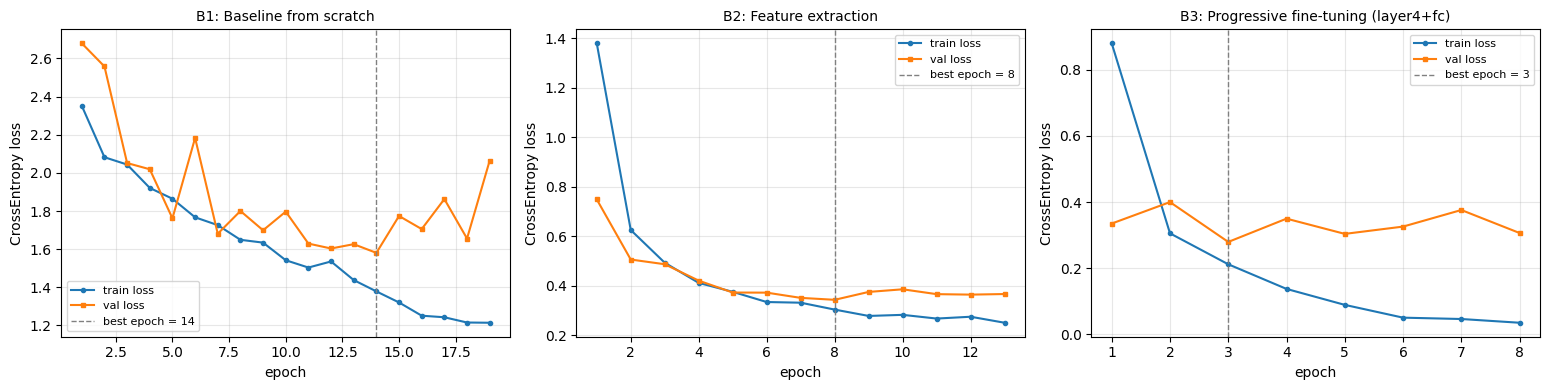

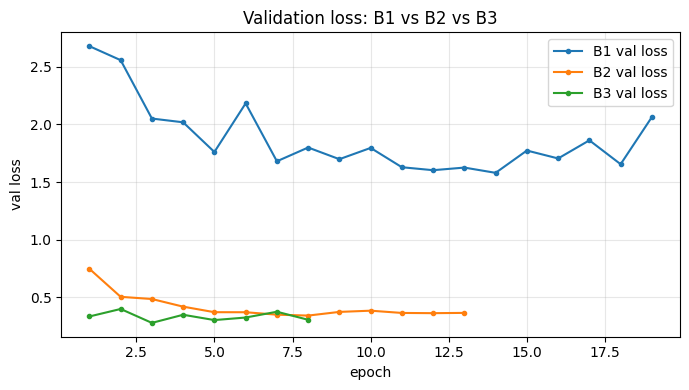

In [ ]:
def plot_loss_curves(codes, fname):
    fig, axes = plt.subplots(1, len(codes), figsize=(5.2 * len(codes), 4), sharey=False)
    axes = np.atleast_1d(axes)

    for ax, c in zip(axes, codes):
        h = pd.DataFrame(RESULTS[c]["history"])

        ax.plot(h["epoch"], h["train_loss"], "o-", ms=3, label="train loss")
        ax.plot(h["epoch"], h["val_loss"], "s-", ms=3, label="val loss")

        be = RESULTS[c]["summary"]["best_epoch"]

        ax.axvline(be, ls="--", c="gray", lw=1, label=f"best epoch = {be}")
        ax.set_title(f"{c}: {RESULTS[c]['summary']['description']}", fontsize=10)
        ax.set_xlabel("epoch"); ax.set_ylabel("CrossEntropy loss"); ax.grid(alpha=0.3); ax.legend(fontsize=8)

    plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=150); plt.show()

plot_loss_curves(["B1", "B2", "B3"], "loss_curves_B1_B2_B3.png")

# Overlay validation loss B1/B2/B3 dalam satu sumbu untuk perbandingan langsung
fig, ax = plt.subplots(figsize=(7, 4))

for c in ["B1", "B2", "B3"]:
    h = pd.DataFrame(RESULTS[c]["history"])
    ax.plot(h["epoch"], h["val_loss"], "o-", ms=3, label=f"{c} val loss")

ax.set_xlabel("epoch"); ax.set_ylabel("val loss"); ax.set_title("Validation loss: B1 vs B2 vs B3"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "val_loss_overlay_B1_B2_B3.png", dpi=150); plt.show()

### Analisis B4: generalization gap dengan vs. tanpa augmentasi

Dua ukuran gap disajikan:
- **Running train acc − val acc** per epoch (train acc diukur saat training, jadi pada B4b diukur pada citra teraugmentasi).
- **Clean train acc − val acc** pada bobot terbaik: train set dievaluasi ulang dengan `eval_transforms`, sehingga kedua kondisi dibandingkan secara adil.

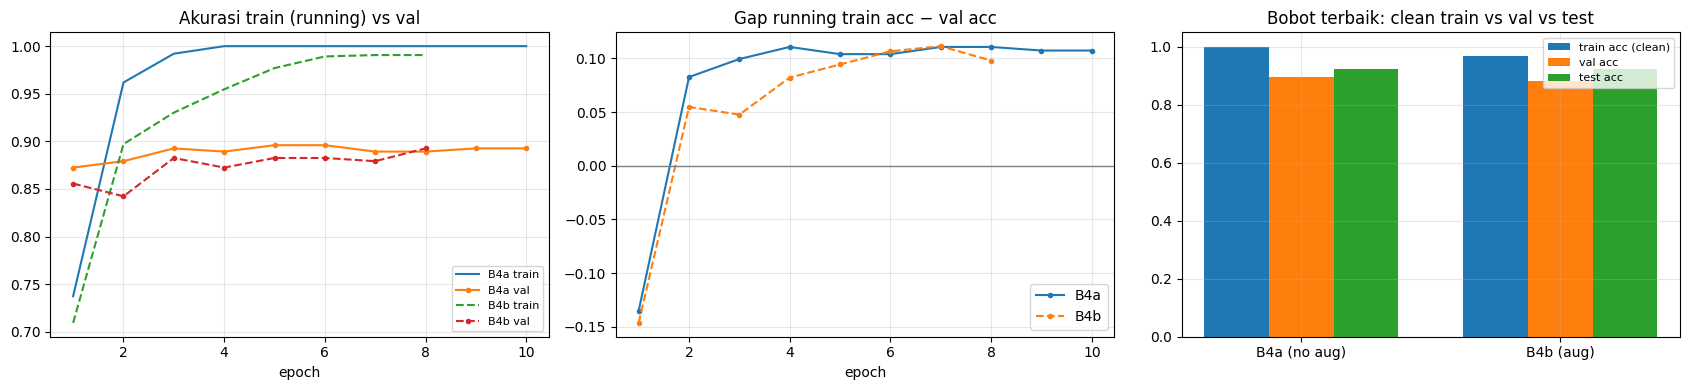

,train_acc_clean,val_acc,test_acc,gap_train_clean_minus_val,test_macro_f1,best_epoch,epochs_run
condition,,,,,,,
B4a,1.0000,0.8960,0.9228,0.1040,0.9213,5,10
B4b,0.9698,0.8826,0.9228,0.0872,0.9223,3,8


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for c, style in [("B4a", "-"), ("B4b", "--")]:
    h = pd.DataFrame(RESULTS[c]["history"])
    axes[0].plot(h["epoch"], h["train_acc"], style, label=f"{c} train")
    axes[0].plot(h["epoch"], h["val_acc"], style, marker="o", ms=3, label=f"{c} val")
    axes[1].plot(h["epoch"], h["train_acc"] - h["val_acc"], style, marker="o", ms=3, label=c)

axes[0].set_title("Akurasi train (running) vs val"); axes[0].set_xlabel("epoch"); axes[0].legend(fontsize=8)
axes[1].axhline(0, c="gray", lw=1); axes[1].set_title("Gap running train acc − val acc"); axes[1].set_xlabel("epoch"); axes[1].legend()

s = summary_df.set_index("condition").loc[["B4a", "B4b"]]
x = np.arange(2); w = 0.25

axes[2].bar(x - w, s["train_acc_clean"], w, label="train acc (clean)")
axes[2].bar(x, s["val_acc"], w, label="val acc")
axes[2].bar(x + w, s["test_acc"], w, label="test acc")
axes[2].set_xticks(x); axes[2].set_xticklabels(["B4a (no aug)", "B4b (aug)"]); axes[2].set_ylim(0, 1.05)
axes[2].set_title("Bobot terbaik: clean train vs val vs test"); axes[2].legend(fontsize=8)

for a in axes: a.grid(alpha=0.3)

plt.tight_layout(); plt.savefig(FIG_DIR / "B4_augmentation_gap.png", dpi=150); plt.show()
display(s[["train_acc_clean", "val_acc", "test_acc", "gap_train_clean_minus_val", "test_macro_f1", "best_epoch", "epochs_run"]])

### Perbandingan seluruh kondisi dan trade-off efisiensi (B5)

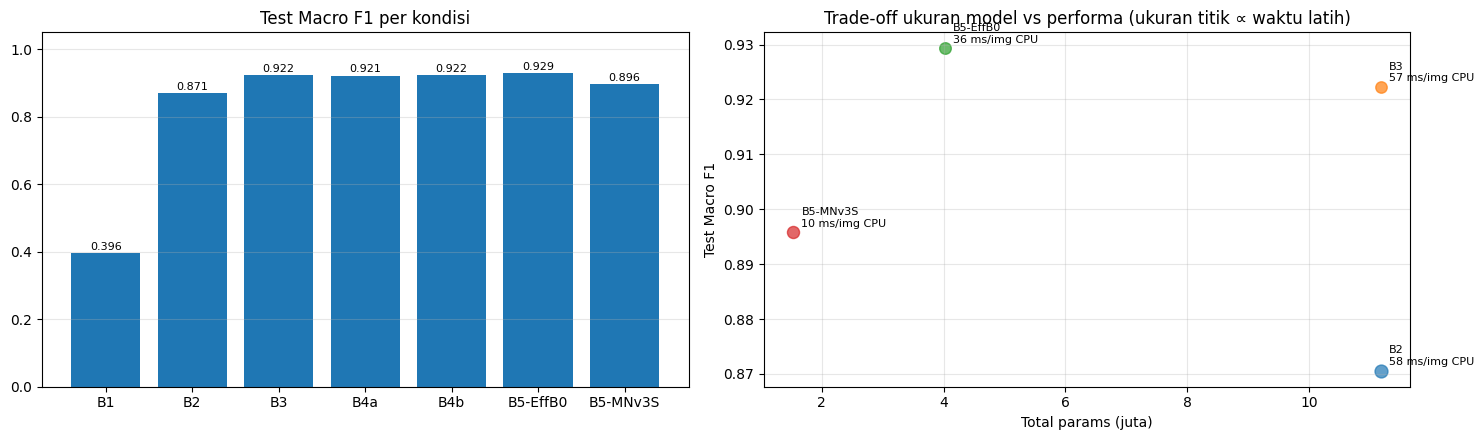

,condition,arch,strategy,trainable_params,total_params,train_time_s,time_per_epoch_s,peak_gpu_mem_mb,latency_gpu_ms_per_batch32,latency_cpu_ms_per_img,val_macro_f1,test_macro_f1
1,B2,resnet18,feature_extraction,5130,11181642,92.22,7.09,288.2,32.76,58.31,0.8707,0.8706
2,B3,resnet18,finetune_last,8398858,11181642,55.07,6.88,384.0,32.16,56.85,0.8822,0.9223
5,B5-EffB0,efficientnet_b0,finetune_last,3168550,4020358,59.35,7.42,409.4,39.78,36.44,0.9294,0.9293
6,B5-MNv3S,mobilenet_v3_small,finetune_last,1337586,1528106,71.30,7.13,151.3,11.05,9.74,0.8571,0.8958


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(summary_df["condition"], summary_df["test_macro_f1"], color="tab:blue")

for i, v in enumerate(summary_df["test_macro_f1"]):
    axes[0].text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=8)

axes[0].set_ylim(0, 1.05); axes[0].set_title("Test Macro F1 per kondisi"); axes[0].grid(axis="y", alpha=0.3)

eff = summary_df[summary_df["condition"].isin(["B2", "B3"]) | summary_df["condition"].str.startswith("B5")]

for _, r in eff.iterrows():
    axes[1].scatter(r["total_params"] / 1e6, r["test_macro_f1"], s=40 + r["train_time_s"] / 2, alpha=0.7)
    axes[1].annotate(f"{r['condition']}\n{r['latency_cpu_ms_per_img']:.0f} ms/img CPU", (r["total_params"] / 1e6, r["test_macro_f1"]),
                     textcoords="offset points", xytext=(6, 4), fontsize=8)

axes[1].set_xlabel("Total params (juta)"); axes[1].set_ylabel("Test Macro F1")
axes[1].set_title("Trade-off ukuran model vs performa (ukuran titik ∝ waktu latih)"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "f1_and_efficiency_tradeoff.png", dpi=150); plt.show()

display(eff[["condition", "arch", "strategy", "trainable_params", "total_params", "train_time_s", "time_per_epoch_s",
             "peak_gpu_mem_mb", "latency_gpu_ms_per_batch32", "latency_cpu_ms_per_img", "val_macro_f1", "test_macro_f1"]])

## 8. C3 — Failure analysis pada model terbaik

Model terbaik dipilih berdasarkan **Macro F1 validasi**. Sampel salah prediksi diurutkan dari *confidence* tertinggi (kesalahan yang paling "yakin" biasanya paling informatif). Kolom `hypothesis` pada `misclassified.csv` sengaja dikosongkan untuk diisi berdasarkan pengamatan Anda sendiri.

Model terbaik (validasi): B5-EffB0 - efficientnet_b0 (finetune_last)
                            precision    recall  f1-score   support

                Abyssinian      1.000     0.967     0.983        30
                    Bengal      0.968     1.000     0.984        30
                    Birman      0.806     0.967     0.879        30
                   Ragdoll      0.929     0.867     0.897        30
                   Siamese      0.962     0.833     0.893        30
 American Pit Bull Terrier      0.960     0.800     0.873        30
Staffordshire Bull Terrier      0.818     0.964     0.885        28
                    Beagle      1.000     0.900     0.947        30
              Basset Hound      0.909     1.000     0.952        30
                   Samoyed      1.000     1.000     1.000        30

                  accuracy                          0.930       298
                 macro avg      0.935     0.930     0.929       298
              weighted avg      0.936     0.9

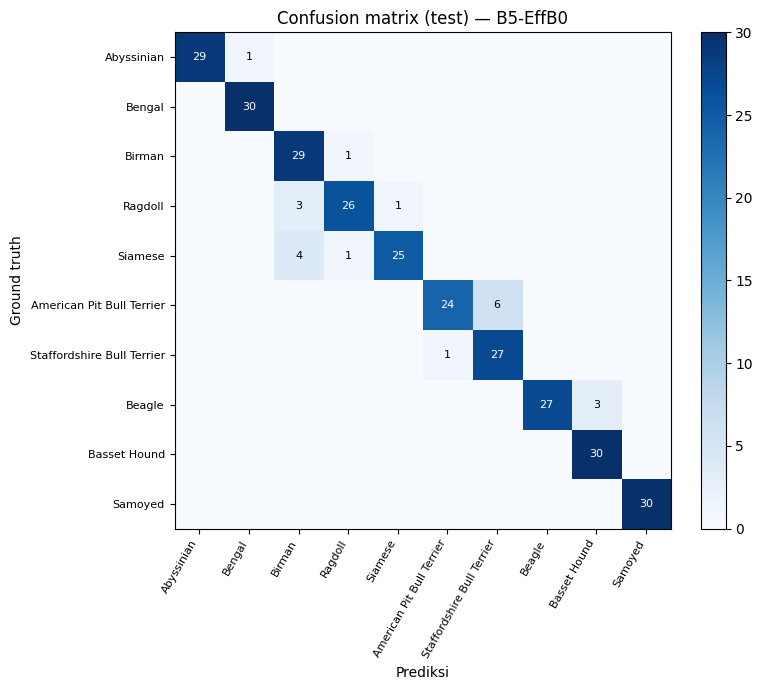

Pasangan kebingungan terbanyak (GT -> Pred):
  American Pit Bull Terrier -> Staffordshire Bull Terrier: 6
  Siamese -> Birman: 4
  Ragdoll -> Birman: 3
  Beagle -> Basset Hound: 3
  Abyssinian -> Bengal: 1
  Birman -> Ragdoll: 1
  Ragdoll -> Siamese: 1
  Siamese -> Ragdoll: 1


In [ ]:
BEST = max(RESULTS, key=lambda c: (RESULTS[c]["summary"]["val_macro_f1"], -RESULTS[c]["summary"]["best_val_loss"]))
print("Model terbaik (validasi):", BEST, "-", RESULTS[BEST]["summary"]["description"])
rb = RESULTS[BEST]
pred = rb["test_probs"].argmax(1)

print(classification_report(rb["test_y"], pred, target_names=SELECTED_CLASSES, digits=3))

cm = confusion_matrix(rb["test_y"], pred, labels=range(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(SELECTED_CLASSES, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(SELECTED_CLASSES, fontsize=8)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Prediksi"); ax.set_ylabel("Ground truth"); ax.set_title(f"Confusion matrix (test) — {BEST}")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig(FIG_DIR / f"confusion_matrix_{BEST}.png", dpi=150); plt.show()

pairs = [(SELECTED_CLASSES[i], SELECTED_CLASSES[j], int(cm[i, j])) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
print("Pasangan kebingungan terbanyak (GT -> Pred):")
for a, b, n in sorted(pairs, key=lambda t: -t[2])[:8]:
    print(f"  {a} -> {b}: {n}")

Total salah prediksi pada test set: 21 dari 298


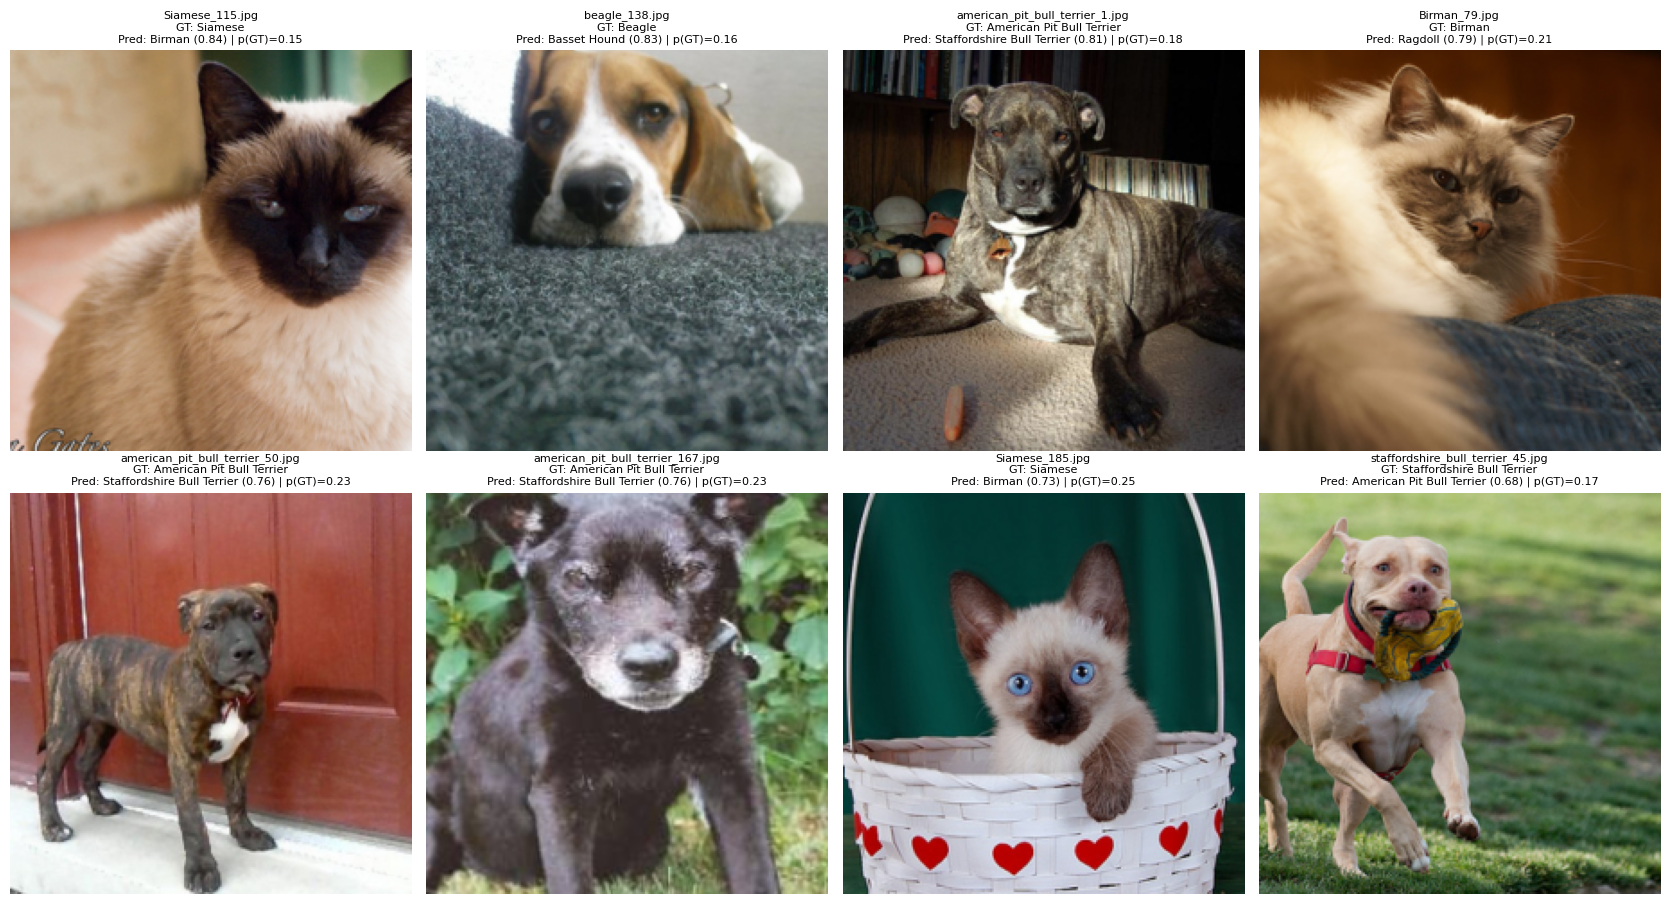

,model,index,image_id,ground_truth,prediction,confidence,p_ground_truth,top3,hypothesis
0,B5-EffB0,413,Siamese_115.jpg,Siamese,Birman,0.8377,0.1538,Birman=0.838; Siamese=0.154; Ragdoll=0.007,
1,B5-EffB0,188,beagle_138.jpg,Beagle,Basset Hound,0.8299,0.1640,Basset Hound=0.830; Beagle=0.164; American Pit...,
2,B5-EffB0,1107,american_pit_bull_terrier_1.jpg,American Pit Bull Terrier,Staffordshire Bull Terrier,0.8122,0.1805,Staffordshire Bull Terrier=0.812; American Pit...,
3,B5-EffB0,1573,Birman_79.jpg,Birman,Ragdoll,0.7867,0.2099,Ragdoll=0.787; Birman=0.210; Abyssinian=0.001,
4,B5-EffB0,1144,american_pit_bull_terrier_50.jpg,American Pit Bull Terrier,Staffordshire Bull Terrier,0.7622,0.2288,Staffordshire Bull Terrier=0.762; American Pit...,
5,B5-EffB0,573,american_pit_bull_terrier_167.jpg,American Pit Bull Terrier,Staffordshire Bull Terrier,0.7574,0.2288,Staffordshire Bull Terrier=0.757; American Pit...,
6,B5-EffB0,927,Siamese_185.jpg,Siamese,Birman,0.7317,0.2458,Birman=0.732; Siamese=0.246; Ragdoll=0.012,
7,B5-EffB0,1925,staffordshire_bull_terrier_45.jpg,Staffordshire Bull Terrier,American Pit Bull Terrier,0.6754,0.1713,American Pit Bull Terrier=0.675; Staffordshire...,


In [ ]:
wrong = np.where(pred != rb["test_y"])[0]
wrong = wrong[np.argsort(-rb["test_probs"][wrong, pred[wrong]])]
show = wrong[:8]
print(f"Total salah prediksi pada test set: {len(wrong)} dari {len(pred)}")

mis_rows = []
if len(show):
    ncol = 4; nrow = int(np.ceil(len(show) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 4.6 * nrow))
    axes = np.atleast_1d(axes).ravel()
    for ax, k in zip(axes, show):
        j = int(rb["test_idx"][k]); gt, pr = rb["test_y"][k], pred[k]
        conf, p_gt = rb["test_probs"][k, pr], rb["test_probs"][k, gt]
        ax.imshow(denormalize(eval_transforms(IMAGES[j]))); ax.axis("off")
        ax.set_title(f"{IMAGE_IDS[j]}\nGT: {SELECTED_CLASSES[gt]}\nPred: {SELECTED_CLASSES[pr]} ({conf:.2f}) | p(GT)={p_gt:.2f}", fontsize=8)
        top3 = np.argsort(-rb["test_probs"][k])[:3]
        mis_rows.append({"model": BEST, "index": j, "image_id": IMAGE_IDS[j], "ground_truth": SELECTED_CLASSES[gt],
                         "prediction": SELECTED_CLASSES[pr], "confidence": round(float(conf), 4), "p_ground_truth": round(float(p_gt), 4),
                         "top3": "; ".join(f"{SELECTED_CLASSES[t]}={rb['test_probs'][k, t]:.3f}" for t in top3),
                         "hypothesis": ""})
    for ax in axes[len(show):]: ax.axis("off")
    plt.tight_layout(); plt.savefig(FIG_DIR / f"misclassified_{BEST}.png", dpi=150); plt.show()
mis_df = pd.DataFrame(mis_rows)
mis_df.to_csv(OUT_DIR / "misclassified.csv", index=False)
display(mis_df)

## 9. C5 (Opsional) — Grad-CAM pada `layer4`: sebelum vs. sesudah fine-tuning

Perbandingan yang adil: **B2** memiliki `layer4` dengan bobot ImageNet asli (beku) tetapi head yang sudah dilatih untuk 10 ras, sedangkan **B3** memiliki `layer4` yang sudah di-fine-tune. Keduanya memakai head untuk 10 kelas yang sama, sehingga perbedaan peta Grad-CAM mencerminkan pergeseran representasi `layer4`. Grad-CAM dihitung terhadap kelas *ground truth*.

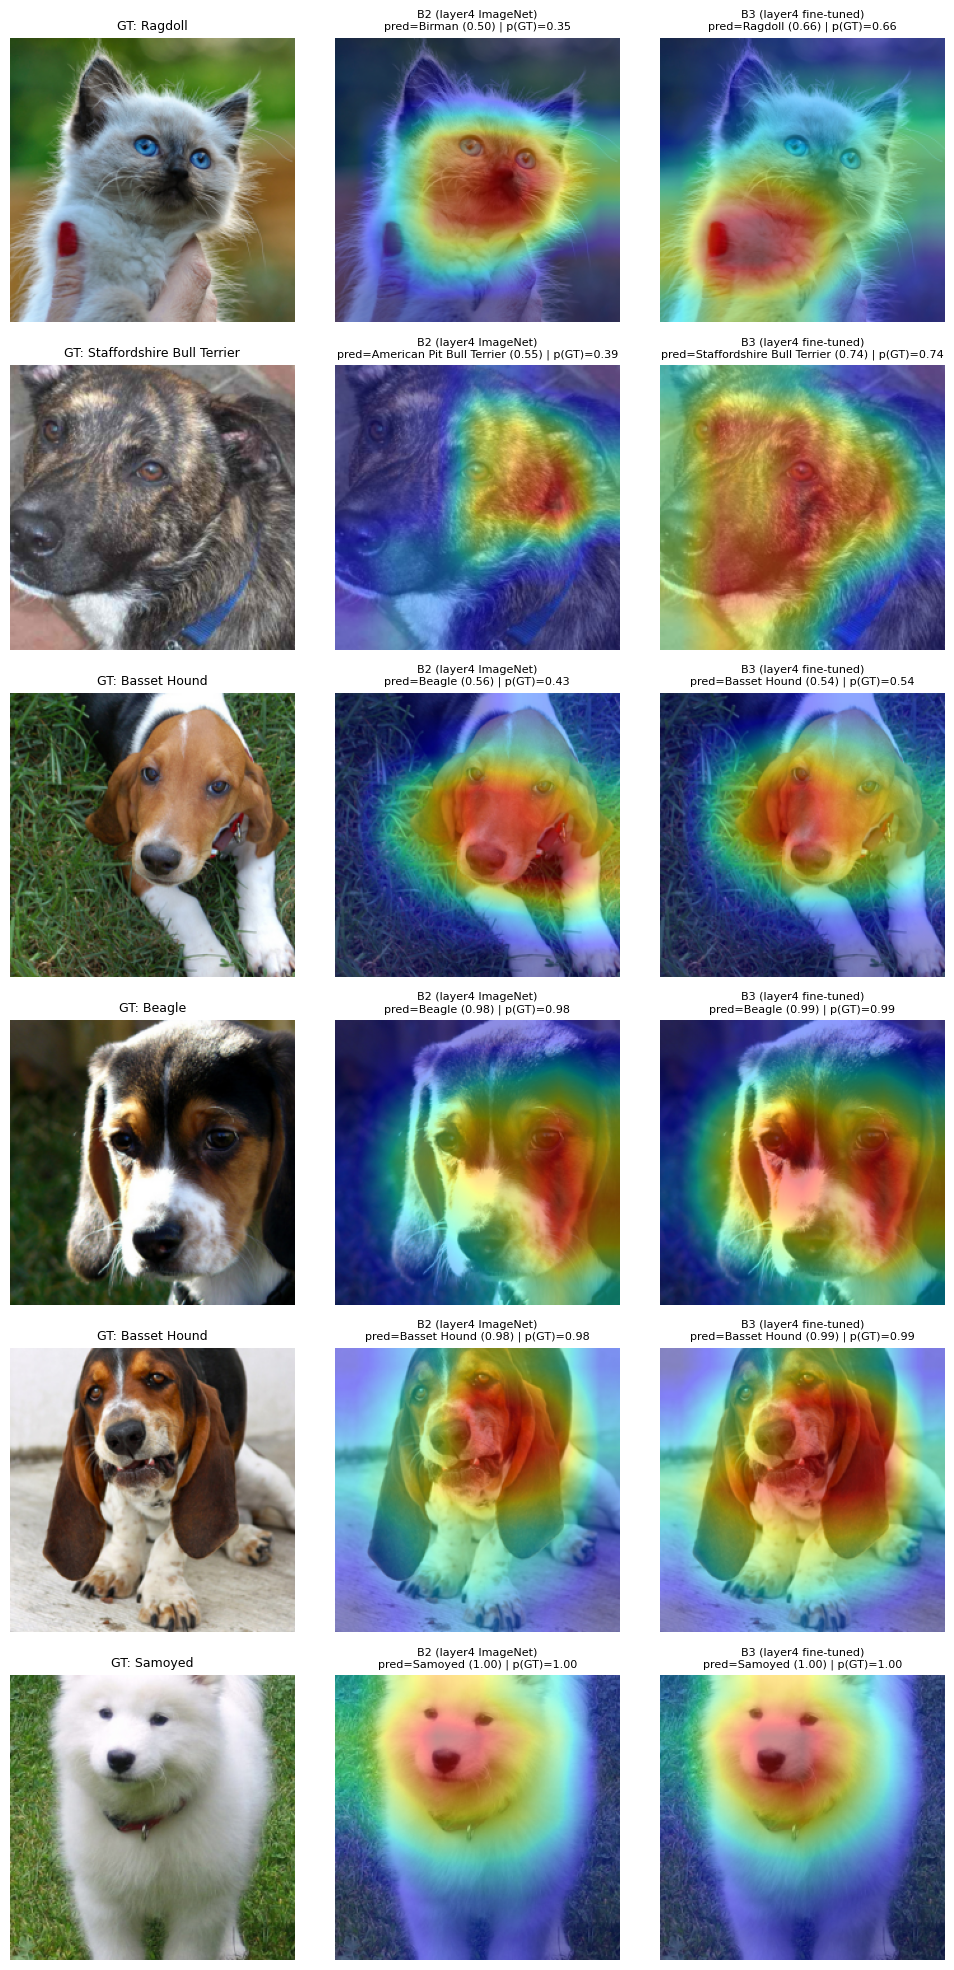

In [ ]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        self.handle = layer.register_forward_hook(self._hook)
    def _hook(self, module, inp, out):
        self.acts = out
        out.register_hook(lambda g: setattr(self, "grads", g))
    def __call__(self, x, target):
        self.model.eval(); self.model.zero_grad(set_to_none=True)
        x = x.clone().requires_grad_(True)   # agar graf terbentuk walau layer4 beku (B2)
        out = self.model(x)
        out[0, target].backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().cpu().numpy(), F.softmax(out, 1)[0].detach().cpu().numpy()
    def remove(self):
        self.handle.remove()

def load_resnet(code):
    m, _, _ = build_model("resnet18", pretrained=False)
    m.load_state_dict(RESULTS[code]["state_dict"]); return m.to(device).eval()

m_b2, m_b3 = load_resnet("B2"), load_resnet("B3")
cam_b2, cam_b3 = GradCAM(m_b2, m_b2.layer4), GradCAM(m_b3, m_b3.layer4)

p2 = RESULTS["B2"]["test_probs"].argmax(1); p3 = RESULTS["B3"]["test_probs"].argmax(1); yt = RESULTS["B3"]["test_y"]
differ = np.where((p2 != yt) & (p3 == yt))[0].tolist()          # B2 salah, B3 benar
rng = np.random.default_rng(SEED)
others = [k for k in rng.permutation(len(yt)).tolist() if k not in differ]
picks = (differ[:3] + others)[:6]

fig, axes = plt.subplots(len(picks), 3, figsize=(10, 3.3 * len(picks)))
axes = np.atleast_2d(axes)
for row, k in zip(axes, picks):
    j = int(RESULTS["B3"]["test_idx"][k]); gt = int(yt[k])
    x = eval_transforms(IMAGES[j]).unsqueeze(0).to(device)
    img = denormalize(x[0].cpu())
    row[0].imshow(img); row[0].set_title(f"GT: {SELECTED_CLASSES[gt]}", fontsize=9)
    for ax, cam_fn, name in [(row[1], cam_b2, "B2 (layer4 ImageNet)"), (row[2], cam_b3, "B3 (layer4 fine-tuned)")]:
        cam, prob = cam_fn(x, gt)
        ax.imshow(img); ax.imshow(cam, cmap="jet", alpha=0.45)
        ax.set_title(f"{name}\npred={SELECTED_CLASSES[prob.argmax()]} ({prob.max():.2f}) | p(GT)={prob[gt]:.2f}", fontsize=8)
    for ax in row: ax.axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "gradcam_layer4_B2_vs_B3.png", dpi=130); plt.show()
cam_b2.remove(); cam_b3.remove()

### Kuantifikasi pergeseran bobot `layer4` setelah fine-tuning (kaitan dengan Slide 28)

Perubahan relatif ‖W<sub>B3</sub> − W<sub>pretrained</sub>‖ / ‖W<sub>pretrained</sub>‖ per lapisan konvolusi di `layer4`. Nilai kecil berarti fine-tuning dengan LR 1e-4 hanya "menggeser" representasi, bukan menimpanya (indikasi tidak terjadi *catastrophic forgetting* yang parah).

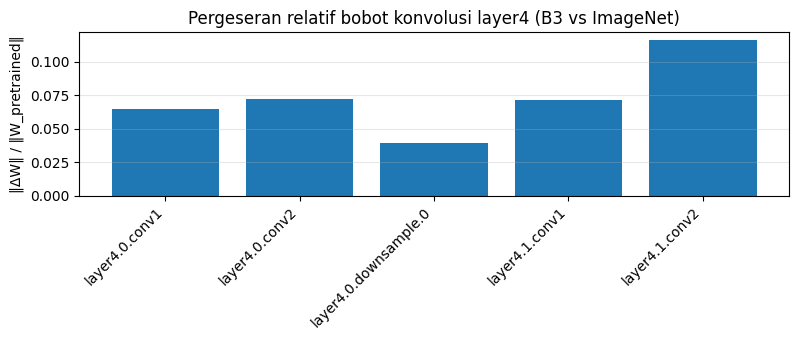

,layer,relative_change
0,layer4.0.conv1,0.065069
1,layer4.0.conv2,0.071961
2,layer4.0.downsample.0,0.038994
3,layer4.1.conv1,0.071726
4,layer4.1.conv2,0.116247


In [ ]:
set_seed(SEED)
ref, _, _ = build_model("resnet18", pretrained=True)
ref_sd, ft_sd = ref.state_dict(), RESULTS["B3"]["state_dict"]
drift = []
for name, w in ref_sd.items():
    if name.startswith("layer4") and name.endswith("weight") and w.dim() == 4:
        rel = (ft_sd[name].float() - w.float()).norm() / (w.float().norm() + 1e-12)
        drift.append({"layer": name.replace(".weight", ""), "relative_change": float(rel)})
drift_df = pd.DataFrame(drift)
drift_df.to_csv(OUT_DIR / "layer4_weight_drift_B3.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(drift_df["layer"], drift_df["relative_change"]); ax.set_ylabel("‖ΔW‖ / ‖W_pretrained‖")
ax.set_title("Pergeseran relatif bobot konvolusi layer4 (B3 vs ImageNet)"); plt.xticks(rotation=45, ha="right")
ax.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.savefig(FIG_DIR / "layer4_weight_drift_B3.png", dpi=150); plt.show()
display(drift_df)

## 10. Ekspor hasil

Membuat `results_export.zip` berisi seluruh log mentah dan gambar (tanpa checkpoint model agar ukurannya kecil). Simpan berkas ini ke repositori dan sertakan di ZIP pengumpulan.

In [ ]:
export_dir = Path("results_export"); shutil.rmtree(export_dir, ignore_errors=True)
shutil.copytree(OUT_DIR, export_dir, ignore=shutil.ignore_patterns("models"))
archive = shutil.make_archive("results_export", "zip", export_dir)
print("Saved:", archive)
for p in sorted(export_dir.rglob("*")):
    if p.is_file(): print(" ", p.relative_to(export_dir))
try:
    from google.colab import files
    files.download(archive)
except Exception:
    pass

Saved: /content/results_export.zip
  config.json
  epoch_log.csv
  figures/B4_augmentation_gap.png
  figures/augmentation_examples.png
  figures/confusion_matrix_B5-EffB0.png
  figures/f1_and_efficiency_tradeoff.png
  figures/gradcam_layer4_B2_vs_B3.png
  figures/layer4_weight_drift_B3.png
  figures/loss_curves_B1_B2_B3.png
  figures/misclassified_B5-EffB0.png
  figures/val_loss_overlay_B1_B2_B3.png
  layer4_weight_drift_B3.csv
  misclassified.csv
  runs/B1.json
  runs/B2.json
  runs/B3.json
  runs/B4a.json
  runs/B4b.json
  runs/B5-EffB0.json
  runs/B5-MNv3S.json
  split.csv
  summary.csv
  summary.json
  summary_table.md
  test_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>